In [52]:
import pandas as pd

In [72]:
df = pd.read_csv("data/evebio_summary_result_table.csv", sep = ",")
df

/opt/tljh/user/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3552: DtypeWarning: Columns (8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,Assay_ID,Compound_ID,Mode,Target_ID,Compound,Result,OMax,AMax,pXC50,Viability,Frequency,Release
0,P00050,EB001601,Agonist,DRD2,Dihydroergotamine Mesylate,Active - Quantified (11pt),86,80.0,>11.6,False,False,2.1
1,P00166,EB000534,Antagonist,ADRA1A,Ingenol Mebutate,Active - Quantified (11pt),64,60.0,>11.1,False,True,4.0
2,P00152,EB000534,Antagonist,LTB4R,Ingenol Mebutate,Active - Quantified (11pt),84,75.0,=10.8,False,True,3.1
3,P00234,EB000263,Antagonist,CHRM4,Benazeprilat,Active - Quantified (11pt),27,90.0,=10.7,False,False,4.0
4,P00074,EB001452,Antagonist,ADRA2A,Methotrexate,Active - Quantified (11pt),8,17.0,=10.6,True,False,2.1
...,...,...,...,...,...,...,...,...,...,...,...,...
238882,P00157,EB001059,Inhibition,Viability,Methyldopa,Inactive (3pt),-7,NaN,NaN,False,False,4.0
238883,P00157,EB001028,Inhibition,Viability,Chlorpropamide,Inactive (3pt),-7,NaN,NaN,False,False,4.0
238884,P00157,EB001392,Inhibition,Viability,Lamotrigine,Inactive (3pt),-7,NaN,NaN,False,False,4.0
238885,P00157,EB001139,Inhibition,Viability,Procaine Hydrochloride,Inactive (3pt),-8,NaN,NaN,False,False,4.0


In [73]:
df = df[df.Target_ID != "Viability"]
df = df[df.Viability != True]
df = df[df.Frequency != True]
df = df[df.Result != 'Likely Inactive (3pt)'].reset_index(drop=True)
df

,Assay_ID,Compound_ID,Mode,Target_ID,Compound,Result,OMax,AMax,pXC50,Viability,Frequency,Release
0,P00050,EB001601,Agonist,DRD2,Dihydroergotamine Mesylate,Active - Quantified (11pt),86,80.0,>11.6,False,False,2.1
1,P00234,EB000263,Antagonist,CHRM4,Benazeprilat,Active - Quantified (11pt),27,90.0,=10.7,False,False,4.0
2,P00035,EB000573,Agonist,ADRB2,Salmeterol,Active - Quantified (11pt),15,27.0,=10.1,False,False,2.1
3,P00050,EB000936,Agonist,DRD2,Aripiprazole,Active - Quantified (11pt),37,36.0,=9.8,False,False,2.1
4,P00129,EB000331,Antagonist,CHRM2,Leuprolide Acetate,Active - Quantified (11pt),20,24.0,=9.8,False,False,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
206135,P00109,EB000724,Antagonist,DRD5,Istradefylline,Inactive (3pt),-41,NaN,NaN,False,False,4.0
206136,P00215,EB001148,Agonist,RORb,Anthralin,Inactive (3pt),-41,NaN,NaN,False,False,4.0
206137,P00233,EB000503,Antagonist,CHRM3,Selumetinib,Inactive (3pt),-42,NaN,NaN,False,False,4.0
206138,P00232,EB000292,Antagonist,APJ,Atovaquone,Inactive (3pt),-44,NaN,NaN,False,False,4.0


In [74]:
df.Result.unique()

array(['Active - Quantified (11pt)', 'Inactive (11pt)',
       'Active - Unquantified (11pt)', 'Active - Unquantified (3pt)',
       'Inactive (3pt)'], dtype=object)

In [75]:
df = df[["Compound", "Result", "Target_ID", "Mode"]].drop_duplicates()
df

,Compound,Result,Target_ID,Mode
0,Dihydroergotamine Mesylate,Active - Quantified (11pt),DRD2,Agonist
1,Benazeprilat,Active - Quantified (11pt),CHRM4,Antagonist
2,Salmeterol,Active - Quantified (11pt),ADRB2,Agonist
3,Aripiprazole,Active - Quantified (11pt),DRD2,Agonist
4,Leuprolide Acetate,Active - Quantified (11pt),CHRM2,Antagonist
...,...,...,...,...
206135,Istradefylline,Inactive (3pt),DRD5,Antagonist
206136,Anthralin,Inactive (3pt),RORb,Agonist
206137,Selumetinib,Inactive (3pt),CHRM3,Antagonist
206138,Atovaquone,Inactive (3pt),APJ,Antagonist


In [76]:
df["Target"] = df["Target_ID"] + "_" + df["Mode"]

# Define the mapping
result_mapping = {
    'Active - Quantified (11pt)': 1,
    'Active - Unquantified (11pt)': 1,
    'Active - Unquantified (3pt)': 1,
    'Inactive (11pt)': 0,
    'Inactive (3pt)': 0
}

# Apply the mapping
df['Result_binary'] = df['Result'].map(result_mapping)


In [77]:
df = df[["Compound", "Result_binary", "Target"]].drop_duplicates()
df

,Compound,Result_binary,Target
0,Dihydroergotamine Mesylate,1,DRD2_Agonist
1,Benazeprilat,1,CHRM4_Antagonist
2,Salmeterol,1,ADRB2_Agonist
3,Aripiprazole,1,DRD2_Agonist
4,Leuprolide Acetate,1,CHRM2_Antagonist
...,...,...,...
206135,Istradefylline,0,DRD5_Antagonist
206136,Anthralin,0,RORb_Agonist
206137,Selumetinib,0,CHRM3_Antagonist
206138,Atovaquone,0,APJ_Antagonist


In [78]:
df = df.pivot_table(
    index='Compound',
    columns='Target',
    values='Result_binary',
    aggfunc='max'  # or 'mean', or 'any' depending on how you want to resolve duplicates
)
df

Target,ADRA1A_Agonist,ADRA1A_Antagonist,ADRA1D_Agonist,ADRA1D_Antagonist,ADRA2A_Agonist,ADRA2A_Antagonist,ADRA2B_Agonist,ADRA2B_Antagonist,ADRA2C_Agonist,ADRA2C_Antagonist,...,TACR3_Agonist,TACR3_Antagonist,TRa_Agonist,TRa_Antagonist,TRb_Agonist,TRb_Antagonist,VDR_Agonist,VDR_Antagonist,rAR_Agonist,rAR_Antagonist
Compound,,,,,,,,,,,,,,,,,,,,,
"(3R,5R)-Rosuvastatin",0.0,1.0,0.0,1.0,0.0,0.0,0.0,NaN,0.0,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"(3R,5S)-Fluvastatin Sodium Salt",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
(E/Z)-Belinostat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"1,2-Diaminocyclohexane",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"1,2-Dimyristoyl-Sn-Glycero-3-Phosphocholine",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zoledronic Acid,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Zolmitriptan,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Zomepirac Sodium Anhydrous,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [79]:
# Remove 'Target' label from column header
df.columns.name = None

# Move index (compound names) to a new column
df = df.reset_index()

In [80]:
df

,Compound,ADRA1A_Agonist,ADRA1A_Antagonist,ADRA1D_Agonist,ADRA1D_Antagonist,ADRA2A_Agonist,ADRA2A_Antagonist,ADRA2B_Agonist,ADRA2B_Antagonist,ADRA2C_Agonist,...,TACR3_Agonist,TACR3_Antagonist,TRa_Agonist,TRa_Antagonist,TRb_Agonist,TRb_Antagonist,VDR_Agonist,VDR_Antagonist,rAR_Agonist,rAR_Antagonist
0,"(3R,5R)-Rosuvastatin",0.0,1.0,0.0,1.0,0.0,0.0,0.0,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"(3R,5S)-Fluvastatin Sodium Salt",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,(E/Z)-Belinostat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,"1,2-Diaminocyclohexane",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,"1,2-Dimyristoyl-Sn-Glycero-3-Phosphocholine",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1392,Zoledronic Acid,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1393,Zolmitriptan,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1394,Zomepirac Sodium Anhydrous,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1395,Zonisamide,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [81]:
df.to_csv("data/evebio_assay_data_names.csv", index=False)

In [195]:
df = pd.read_csv("data/evebio_assay_data_smiles.csv").dropna(subset=["SMILES"]).reset_index(drop=True)
df

,Compound,SMILES,QSAR_READY_SMILES,ADRA1A_Agonist,ADRA1A_Antagonist,ADRA1D_Agonist,ADRA1D_Antagonist,ADRA2A_Agonist,ADRA2A_Antagonist,ADRA2B_Agonist,...,TACR3_Agonist,TACR3_Antagonist,TRa_Agonist,TRa_Antagonist,TRb_Agonist,TRb_Antagonist,VDR_Agonist,VDR_Antagonist,rAR_Agonist,rAR_Antagonist
0,"1,2-Diaminocyclohexane",NC1CCCCC1N,NC1CCCCC1N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,21-Desacetyldeflazacort,[H][C@@]12C[C@@]3([H])[C@]4([H])CCC5=CC(=O)C=C...,CC1=NC2(C(CC3C4CCC5=CC(=O)C=CC5(C)C4C(O)CC23C)...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Abacavir Sulfate,[O-]S([O-])(=O)=O.[NH3+]C1=NC(NC2CC2)=C2N=CN([...,NC1=NC(NC2CC2)=C2N=CN(C3CC(CO)C=C3)C2=N1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Abiraterone,[H][C@@]12CC=C(C3=CN=CC=C3)[C@@]1(C)CC[C@@]1([...,CC12CCC3C(CC=C4CC(O)CCC34C)C1CC=C2C1=CC=CN=C1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0
4,Acalabrutinib,CC#CC(=O)N1CCC[C@H]1C1=NC(=C2N1C=CN=C2N)C1=CC=...,NaN,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1292,Ziprasidone,ClC1=C(CCN2CCN(CC2)C2=NSC3=CC=CC=C23)C=C2CC(=O...,ClC1=C(CCN2CCN(CC2)C2=NSC3=CC=CC=C23)C=C2CC(=O...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0
1293,Zoledronic Acid,O.OC(CN1C=CN=C1)(P(O)(O)=O)P(O)(O)=O,OC(CN1C=CN=C1)(P(O)(O)=O)P(O)(O)=O,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1294,Zolmitriptan,CN(C)CCC1=CNC2=C1C=C(C[C@H]1COC(=O)N1)C=C2,CN(C)CCC1=CNC2=CC=C(CC3COC(=O)N3)C=C12,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1295,Zonisamide,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [196]:
# Function to convert SMILES to InChIKey
from rdkit import Chem
from rdkit.Chem import inchi
from pandarallel import pandarallel
pandarallel.initialize()

def smiles_to_inchikey(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles, sanitize=True)
        if mol is None:
            return 'CANNOT_CONVERT'
        # Optionally: kekulize or re-canonize
        Chem.SanitizeMol(mol)
        return inchi.MolToInchiKey(mol)
    except:
        return 'CANNOT_CONVERT'
df['InChIKey'] =df['SMILES'].parallel_apply(smiles_to_inchikey)
df

INFO: Pandarallel will run on 40 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


,Compound,SMILES,QSAR_READY_SMILES,ADRA1A_Agonist,ADRA1A_Antagonist,ADRA1D_Agonist,ADRA1D_Antagonist,ADRA2A_Agonist,ADRA2A_Antagonist,ADRA2B_Agonist,...,TACR3_Antagonist,TRa_Agonist,TRa_Antagonist,TRb_Agonist,TRb_Antagonist,VDR_Agonist,VDR_Antagonist,rAR_Agonist,rAR_Antagonist,InChIKey
0,"1,2-Diaminocyclohexane",NC1CCCCC1N,NC1CCCCC1N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,SSJXIUAHEKJCMH-UHFFFAOYSA-N
1,21-Desacetyldeflazacort,[H][C@@]12C[C@@]3([H])[C@]4([H])CCC5=CC(=O)C=C...,CC1=NC2(C(CC3C4CCC5=CC(=O)C=CC5(C)C4C(O)CC23C)...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,KENSGCYKTRNIST-RVUAFKSESA-N
2,Abacavir Sulfate,[O-]S([O-])(=O)=O.[NH3+]C1=NC(NC2CC2)=C2N=CN([...,NC1=NC(NC2CC2)=C2N=CN(C3CC(CO)C=C3)C2=N1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,WMHSRBZIJNQHKT-FFKFEZPRSA-N
3,Abiraterone,[H][C@@]12CC=C(C3=CN=CC=C3)[C@@]1(C)CC[C@@]1([...,CC12CCC3C(CC=C4CC(O)CCC34C)C1CC=C2C1=CC=CN=C1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,GZOSMCIZMLWJML-VJLLXTKPSA-N
4,Acalabrutinib,CC#CC(=O)N1CCC[C@H]1C1=NC(=C2N1C=CN=C2N)C1=CC=...,NaN,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,WDENQIQQYWYTPO-IBGZPJMESA-N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1292,Ziprasidone,ClC1=C(CCN2CCN(CC2)C2=NSC3=CC=CC=C23)C=C2CC(=O...,ClC1=C(CCN2CCN(CC2)C2=NSC3=CC=CC=C23)C=C2CC(=O...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,MVWVFYHBGMAFLY-UHFFFAOYSA-N
1293,Zoledronic Acid,O.OC(CN1C=CN=C1)(P(O)(O)=O)P(O)(O)=O,OC(CN1C=CN=C1)(P(O)(O)=O)P(O)(O)=O,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,FUXFIVRTGHOMSO-UHFFFAOYSA-N
1294,Zolmitriptan,CN(C)CCC1=CNC2=C1C=C(C[C@H]1COC(=O)N1)C=C2,CN(C)CCC1=CNC2=CC=C(CC3COC(=O)N3)C=C12,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ULSDMUVEXKOYBU-ZDUSSCGKSA-N
1295,Zonisamide,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,UBQNRHZMVUUOMG-UHFFFAOYSA-N


In [197]:
df["ADRA1A_Antagonist"].value_counts()

0.0    700
1.0    196
Name: ADRA1A_Antagonist, dtype: int64

In [198]:
CP = pd.read_csv("../Cell_Painting_Median_Features_Median_doses.csv")

In [199]:
import pandas as pd
from rdkit import Chem
from pandarallel import pandarallel

# Initialize pandarallel
pandarallel.initialize()

# Function to convert InChI to InChIKey
def inchi_to_inchikey(inchi):
    mol = Chem.inchi.MolFromInchi(inchi)
    if mol is not None:
        return Chem.MolToInchiKey(mol)
    else:
        return None
    
# Apply the function to the dataframe in parallel
CP['InChIKey'] = CP['InChICode_standardised'].parallel_apply(inchi_to_inchikey)

CP

INFO: Pandarallel will run on 40 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


[18:23:29] WARNING: not removing hydrogen atom without neighbors
[18:23:29] WARNING: not removing hydrogen atom without neighbors


,InChICode_standardised,index,Metadata_mmoles_per_liter,Cells_AreaShape_Area,Cells_AreaShape_Center_X,Cells_AreaShape_Center_Y,Cells_AreaShape_Compactness,Cells_AreaShape_Eccentricity,Cells_AreaShape_EulerNumber,Cells_AreaShape_Extent,...,Nuclei_Texture_Variance_ER_10_0,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0,InChIKey
0,InChI=1S/C12H15N3O2S/c1-7(2)18-8-4-5-9-10(6-8)...,960.0,5.000000,1728.953125,-1.375000,-25.445312,-0.067918,-0.062396,0.0,0.026443,...,0.314918,0.222859,0.280258,0.192997,0.144917,0.168085,-0.332871,-0.314733,-0.313477,SXJIZQPZESTWLD-UHFFFAOYSA-N
1,InChI=1S/C12H18N4O3/c1-7(2)5-16-10-9(11(17)15(...,1036.0,5.000000,-272.074219,11.464844,-1.628906,-0.001808,-0.006674,0.0,-0.001405,...,0.023860,-0.016903,-0.017773,-0.028029,-0.038308,-0.041455,-0.070389,-0.067789,-0.071673,NBLBCGUCPBXKOV-UHFFFAOYSA-N
2,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4942.5,4.973595,101.958984,15.673828,-2.314453,0.010687,0.013397,0.0,-0.003746,...,-0.014119,0.035703,0.016875,-0.039304,-0.070028,-0.062892,-0.015647,-0.038908,-0.026464,FOLOUAULJSJVDY-GZBFAFLISA-N
3,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4944.5,4.912934,-109.708984,-10.203125,1.718750,0.025025,0.014627,0.0,-0.007164,...,0.046218,0.031759,0.037029,-0.051411,-0.083061,-0.071562,-0.024598,-0.052021,-0.043327,FOLOUAULJSJVDY-IPYPFGDCSA-N
4,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4949.5,5.012874,-234.222656,8.873047,3.308594,0.010192,0.005251,0.0,-0.003173,...,-0.072889,-0.030955,-0.037623,-0.009460,0.004604,-0.010465,-0.031869,-0.025910,-0.014907,FOLOUAULJSJVDY-NFAWXSAZSA-N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30399,InChI=1S/C9H9N5OS2/c10-12-8(16)11-6-3-1-2-5(4-...,30588.0,5.000000,-226.027344,-18.847656,-0.511719,-0.005827,0.004864,0.0,0.003590,...,-0.114357,-0.123664,-0.127474,-0.069665,-0.056972,-0.044186,-0.019668,-0.091541,-0.062515,LHXWPDUWZAYBJV-UHFFFAOYSA-N
30400,InChI=1S/C9H9NO/c11-6-7-5-10-9-4-2-1-3-8(7)9/h...,30589.0,5.000000,254.769531,18.886719,-3.589844,0.027814,0.016943,0.0,-0.000781,...,-0.079942,-0.018155,-0.017759,-0.118369,-0.046322,-0.023926,0.033498,0.051214,0.016060,IVYPNXXAYMYVSP-UHFFFAOYSA-N
30401,InChI=1S/C9H9NO2/c10-8-3-1-2-7(6-8)4-5-9(11)12...,30590.0,5.000000,238.574219,-0.699219,6.625000,0.005228,0.008800,0.0,0.002336,...,-0.107812,-0.107077,-0.138399,0.168811,0.216703,0.195851,-0.063656,-0.042877,-0.071681,JNXMJSYJCFTLJB-SNAWJCMRSA-N
30402,InChI=1S/C9H9NO3S/c1-6(11)5-14-8-3-2-7(4-10-8)...,30591.0,5.000000,-238.945312,5.476562,0.089844,0.018032,0.012711,0.0,-0.004635,...,-0.070647,-0.095379,-0.102060,0.023423,0.049321,0.041996,0.023470,0.058959,0.065934,LRBIKSYRCFHKBN-UHFFFAOYSA-N


In [200]:
CP_features = ['Cells_Number_Object_Number',
             'Cells_Neighbors_FirstClosestObjectNumber_5',
 'Cells_Neighbors_FirstClosestObjectNumber_Adjacent',
 'Cells_Neighbors_SecondClosestObjectNumber_5',
 'Cells_Neighbors_SecondClosestObjectNumber_Adjacent',
 'Cells_Parent_Nuclei',
 'Cytoplasm_Number_Object_Number',
 'Cytoplasm_Parent_Cells',
 'Cytoplasm_Parent_Nuclei',
 'Nuclei_Neighbors_FirstClosestObjectNumber_1',
 'Nuclei_Neighbors_SecondClosestObjectNumber_1',
 'Nuclei_Number_Object_Number',
 ]

CP_new = CP[CP_features + ["InChIKey"]]
CP_new

,Cells_Number_Object_Number,Cells_Neighbors_FirstClosestObjectNumber_5,Cells_Neighbors_FirstClosestObjectNumber_Adjacent,Cells_Neighbors_SecondClosestObjectNumber_5,Cells_Neighbors_SecondClosestObjectNumber_Adjacent,Cells_Parent_Nuclei,Cytoplasm_Number_Object_Number,Cytoplasm_Parent_Cells,Cytoplasm_Parent_Nuclei,Nuclei_Neighbors_FirstClosestObjectNumber_1,Nuclei_Neighbors_SecondClosestObjectNumber_1,Nuclei_Number_Object_Number,InChIKey
0,-26.265625,-26.218750,-26.218750,-27.265625,-27.265625,-26.265625,-26.265625,-26.265625,-26.265625,-26.187500,-26.218750,-26.265625,SXJIZQPZESTWLD-UHFFFAOYSA-N
1,4.812500,4.960938,4.960938,5.843750,5.843750,4.828125,4.812500,4.828125,4.828125,4.726562,4.718750,4.812500,NBLBCGUCPBXKOV-UHFFFAOYSA-N
2,-2.435547,-2.722656,-2.722656,-2.509766,-2.509766,-2.435547,-2.435547,-2.435547,-2.435547,-2.449219,-2.455078,-2.435547,FOLOUAULJSJVDY-GZBFAFLISA-N
3,0.964844,1.183594,1.183594,0.726562,0.726562,0.968750,0.964844,0.968750,0.968750,1.228516,0.324219,0.964844,FOLOUAULJSJVDY-IPYPFGDCSA-N
4,2.212891,2.699219,2.699219,2.539062,2.539062,2.216797,2.212891,2.216797,2.216797,3.253906,2.826172,2.212891,FOLOUAULJSJVDY-NFAWXSAZSA-N
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30399,2.714844,3.257812,3.257812,3.324219,3.324219,2.714844,2.714844,2.714844,2.714844,3.773438,2.773438,2.714844,LHXWPDUWZAYBJV-UHFFFAOYSA-N
30400,-10.828125,-10.828125,-10.828125,-9.937500,-9.937500,-10.828125,-10.828125,-10.828125,-10.828125,-10.679688,-10.460938,-10.828125,IVYPNXXAYMYVSP-UHFFFAOYSA-N
30401,-0.078125,-1.109375,-1.109375,0.382812,0.382812,-0.078125,-0.078125,-0.078125,-0.078125,-0.132812,-1.000000,-0.078125,JNXMJSYJCFTLJB-SNAWJCMRSA-N
30402,-0.078125,-0.722656,-0.722656,-0.015625,-0.015625,-0.078125,-0.078125,-0.078125,-0.078125,-0.398438,0.101562,-0.078125,LRBIKSYRCFHKBN-UHFFFAOYSA-N


In [201]:
df = pd.merge(df ,CP_new, left_on="InChIKey", right_on="InChIKey", how="inner").reset_index(drop=True)
df

,Compound,SMILES,QSAR_READY_SMILES,ADRA1A_Agonist,ADRA1A_Antagonist,ADRA1D_Agonist,ADRA1D_Antagonist,ADRA2A_Agonist,ADRA2A_Antagonist,ADRA2B_Agonist,...,Cells_Neighbors_FirstClosestObjectNumber_Adjacent,Cells_Neighbors_SecondClosestObjectNumber_5,Cells_Neighbors_SecondClosestObjectNumber_Adjacent,Cells_Parent_Nuclei,Cytoplasm_Number_Object_Number,Cytoplasm_Parent_Cells,Cytoplasm_Parent_Nuclei,Nuclei_Neighbors_FirstClosestObjectNumber_1,Nuclei_Neighbors_SecondClosestObjectNumber_1,Nuclei_Number_Object_Number
0,Acenocoumarol,CC(=O)CC(C1=CC=C(C=C1)[N+]([O-])=O)C1=C(O)C2=C...,CC(=O)CC(C1C(=O)OC2=CC=CC=C2C1=O)C1=CC=C(C=C1)...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,6.531250,5.859375,5.859375,6.546875,6.546875,6.546875,6.546875,6.085938,7.906250,6.546875
1,Acetaminophen,CC(=O)NC1=CC=C(O)C=C1,CC(=O)NC1=CC=C(O)C=C1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-4.074219,-4.253906,-4.253906,-4.164062,-4.164062,-4.164062,-4.164062,-3.585938,-4.132812,-4.164062
2,Acetazolamide,CC(=O)NC1=NN=C(S1)S(N)(=O)=O,CC(=O)NC1=NN=C(S1)S(N)(=O)=O,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-18.492188,-17.812500,-17.812500,-17.882812,-17.882812,-17.882812,-17.882812,-18.007812,-17.882812,-17.882812
3,Acetohexamide,CC(=O)C1=CC=C(C=C1)S(=O)(=O)NC(=O)NC1CCCCC1,CC(=O)C1=CC=C(C=C1)S(=O)(=O)NC(=O)NC1CCCCC1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.898438,-0.054688,-0.054688,-0.117188,-0.117188,-0.117188,-0.117188,-0.085938,0.367188,-0.117188
4,Albendazole,CCCSC1=CC=C2NC(NC(=O)OC)=NC2=C1,CCCSC1=CC=C2NC(NC(=O)OC)=NC2=C1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-36.914062,-36.515625,-36.515625,-36.789062,-36.789062,-36.789062,-36.789062,-36.871094,-36.382812,-36.789062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,Warfarin,CC(=O)CC(C1=CC=CC=C1)C1=C(O)C2=CC=CC=C2OC1=O,CC(=O)CC(C1C(=O)OC2=CC=CC=C2C1=O)C1=CC=CC=C1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.384615,5.000000,5.000000,5.061538,5.061538,5.061538,5.061538,4.165385,5.553846,5.061538
275,Yohimbine,[H][C@@]12CC[C@H](O)[C@H](C(=O)OC)[C@@]1([H])C...,COC(=O)C1C(O)CCC2CN3CCC4=C(NC5=CC=CC=C45)C3CC12,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,-0.039062,0.296875,0.296875,-0.039062,-0.039062,-0.039062,-0.039062,-0.640625,0.539062,-0.039062
276,Zidovudine,CC1=CN([C@H]2C[C@H](N=[N+]=[N-])[C@@H](CO)O2)C...,CC1=CN(C2CC(N=[N+]=[N-])C(CO)O2)C(=O)N=C1O,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.210938,0.695312,0.695312,0.578125,0.570312,0.578125,0.578125,0.406250,-0.101562,0.570312
277,Zonisamide,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.976562,2.640625,2.640625,1.562500,1.562500,1.562500,1.562500,1.906250,1.468750,1.562500


In [202]:
df.columns[3:-13]

Index(['ADRA1A_Agonist', 'ADRA1A_Antagonist', 'ADRA1D_Agonist',
       'ADRA1D_Antagonist', 'ADRA2A_Agonist', 'ADRA2A_Antagonist',
       'ADRA2B_Agonist', 'ADRA2B_Antagonist', 'ADRA2C_Agonist',
       'ADRA2C_Antagonist',
       ...
       'TACR3_Agonist', 'TACR3_Antagonist', 'TRa_Agonist', 'TRa_Antagonist',
       'TRb_Agonist', 'TRb_Antagonist', 'VDR_Agonist', 'VDR_Antagonist',
       'rAR_Agonist', 'rAR_Antagonist'],
      dtype='object', length=170)

In [203]:
# Create a list to keep track of columns meeting the condition
columns_to_keep = []

# Iterate over columns starting from the 6th column onward
for col in df.columns[3:-13]:
    # Check if all value counts are at least 20
    if (df[col].value_counts() >= 20).all() and (df[col].nunique() > 1):
        columns_to_keep.append(col)

# Subset the DataFrame to include only these columns
filtered_df = df[["InChIKey"] + columns_to_keep + CP_features]

# Display the resulting DataFrame
filtered_df = filtered_df.dropna(axis=1, how="all")

for col in filtered_df.columns[3:-13]:
    print(filtered_df[col].value_counts())

0.0    213
1.0     24
Name: ADRA2B_Antagonist, dtype: int64
0.0    221
1.0     22
Name: CAR_Antagonist, dtype: int64
0.0    235
1.0     24
Name: ERa_Antagonist, dtype: int64
0.0    226
1.0     32
Name: ERb_Antagonist, dtype: int64
0.0    204
1.0     24
Name: GPR119_Antagonist, dtype: int64
0.0    248
1.0     23
Name: GR_Agonist, dtype: int64
0.0    197
1.0     23
Name: HCTR1_Antagonist, dtype: int64
0.0    221
1.0     45
Name: PPARa_Antagonist, dtype: int64
0.0    234
1.0     21
Name: PPARg_Antagonist, dtype: int64
0.0    242
1.0     33
Name: PR_Agonist, dtype: int64
0.0    230
1.0     31
Name: PR_Antagonist, dtype: int64
0.0    170
1.0     89
Name: PXR_Agonist, dtype: int64
0.0    216
1.0     26
Name: RARa_Antagonist, dtype: int64
0.0    231
1.0     24
Name: RARb_Antagonist, dtype: int64
0.0    234
1.0     35
Name: RARg_Antagonist, dtype: int64
0.0    234
1.0     32
Name: RORa_Antagonist, dtype: int64
0.0    221
1.0     40
Name: RORb_Antagonist, dtype: int64
0.0    235
1.0     28
Name

In [204]:
filtered_df

,InChIKey,ADRA1A_Antagonist,ADRA2A_Antagonist,ADRA2B_Antagonist,CAR_Antagonist,ERa_Antagonist,ERb_Antagonist,GPR119_Antagonist,GR_Agonist,HCTR1_Antagonist,...,Cells_Neighbors_FirstClosestObjectNumber_Adjacent,Cells_Neighbors_SecondClosestObjectNumber_5,Cells_Neighbors_SecondClosestObjectNumber_Adjacent,Cells_Parent_Nuclei,Cytoplasm_Number_Object_Number,Cytoplasm_Parent_Cells,Cytoplasm_Parent_Nuclei,Nuclei_Neighbors_FirstClosestObjectNumber_1,Nuclei_Neighbors_SecondClosestObjectNumber_1,Nuclei_Number_Object_Number
0,VABCILAOYCMVPS-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,6.531250,5.859375,5.859375,6.546875,6.546875,6.546875,6.546875,6.085938,7.906250,6.546875
1,RZVAJINKPMORJF-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-4.074219,-4.253906,-4.253906,-4.164062,-4.164062,-4.164062,-4.164062,-3.585938,-4.132812,-4.164062
2,BZKPWHYZMXOIDC-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-18.492188,-17.812500,-17.812500,-17.882812,-17.882812,-17.882812,-17.882812,-18.007812,-17.882812,-17.882812
3,VGZSUPCWNCWDAN-UHFFFAOYSA-N,1.0,1.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,...,0.898438,-0.054688,-0.054688,-0.117188,-0.117188,-0.117188,-0.117188,-0.085938,0.367188,-0.117188
4,HXHWSAZORRCQMX-UHFFFAOYSA-N,NaN,NaN,NaN,0.0,0.0,0.0,NaN,0.0,NaN,...,-36.914062,-36.515625,-36.515625,-36.789062,-36.789062,-36.789062,-36.789062,-36.871094,-36.382812,-36.789062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,PJVWKTKQMONHTI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,4.384615,5.000000,5.000000,5.061538,5.061538,5.061538,5.061538,4.165385,5.553846,5.061538
275,BLGXFZZNTVWLAY-SCYLSFHTSA-N,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,-0.039062,0.296875,0.296875,-0.039062,-0.039062,-0.039062,-0.039062,-0.640625,0.539062,-0.039062
276,HBOMLICNUCNMMY-XLPZGREQSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.210938,0.695312,0.695312,0.578125,0.570312,0.578125,0.578125,0.406250,-0.101562,0.570312
277,UBQNRHZMVUUOMG-UHFFFAOYSA-N,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,1.976562,2.640625,2.640625,1.562500,1.562500,1.562500,1.562500,1.906250,1.468750,1.562500


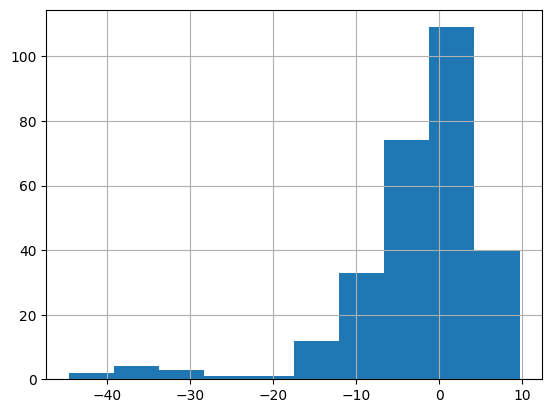

In [205]:
import matplotlib.pyplot as plt

filtered_df.Cells_Number_Object_Number.hist()
plt.show()

In [206]:
threshold = filtered_df.Cells_Number_Object_Number.mean() - 2*filtered_df.Cells_Number_Object_Number.std()
threshold

-19.321262173643454

In [207]:
#Remove compounds with low cell count from Cell Painting space
filtered_df = filtered_df[filtered_df.Cells_Number_Object_Number>threshold].reset_index(drop=True)
filtered_df

,InChIKey,ADRA1A_Antagonist,ADRA2A_Antagonist,ADRA2B_Antagonist,CAR_Antagonist,ERa_Antagonist,ERb_Antagonist,GPR119_Antagonist,GR_Agonist,HCTR1_Antagonist,...,Cells_Neighbors_FirstClosestObjectNumber_Adjacent,Cells_Neighbors_SecondClosestObjectNumber_5,Cells_Neighbors_SecondClosestObjectNumber_Adjacent,Cells_Parent_Nuclei,Cytoplasm_Number_Object_Number,Cytoplasm_Parent_Cells,Cytoplasm_Parent_Nuclei,Nuclei_Neighbors_FirstClosestObjectNumber_1,Nuclei_Neighbors_SecondClosestObjectNumber_1,Nuclei_Number_Object_Number
0,VABCILAOYCMVPS-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,6.531250,5.859375,5.859375,6.546875,6.546875,6.546875,6.546875,6.085938,7.906250,6.546875
1,RZVAJINKPMORJF-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-4.074219,-4.253906,-4.253906,-4.164062,-4.164062,-4.164062,-4.164062,-3.585938,-4.132812,-4.164062
2,BZKPWHYZMXOIDC-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-18.492188,-17.812500,-17.812500,-17.882812,-17.882812,-17.882812,-17.882812,-18.007812,-17.882812,-17.882812
3,VGZSUPCWNCWDAN-UHFFFAOYSA-N,1.0,1.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,...,0.898438,-0.054688,-0.054688,-0.117188,-0.117188,-0.117188,-0.117188,-0.085938,0.367188,-0.117188
4,NDAUXUAQIAJITI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-9.421875,-8.875000,-8.875000,-8.921875,-8.921875,-8.921875,-8.921875,-9.468750,-8.687500,-8.921875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,PJVWKTKQMONHTI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,4.384615,5.000000,5.000000,5.061538,5.061538,5.061538,5.061538,4.165385,5.553846,5.061538
265,BLGXFZZNTVWLAY-SCYLSFHTSA-N,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,-0.039062,0.296875,0.296875,-0.039062,-0.039062,-0.039062,-0.039062,-0.640625,0.539062,-0.039062
266,HBOMLICNUCNMMY-XLPZGREQSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.210938,0.695312,0.695312,0.578125,0.570312,0.578125,0.578125,0.406250,-0.101562,0.570312
267,UBQNRHZMVUUOMG-UHFFFAOYSA-N,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,1.976562,2.640625,2.640625,1.562500,1.562500,1.562500,1.562500,1.906250,1.468750,1.562500


In [208]:
filtered_df.to_csv("CP_count_EveBio.csv", index=False)

In [213]:
inchiandassays_list = filtered_df.columns.to_list()[:25]
filtered_df = filtered_df[inchiandassays_list]
filtered_df

,InChIKey,ADRA1A_Antagonist,ADRA2A_Antagonist,ADRA2B_Antagonist,CAR_Antagonist,ERa_Antagonist,ERb_Antagonist,GPR119_Antagonist,GR_Agonist,HCTR1_Antagonist,...,RARa_Antagonist,RARb_Antagonist,RARg_Antagonist,RORa_Antagonist,RORb_Antagonist,RORg_Antagonist,RXRa_Antagonist,RXRb_Antagonist,RXRg_Antagonist,SF1_Antagonist
0,VABCILAOYCMVPS-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,RZVAJINKPMORJF-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,BZKPWHYZMXOIDC-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,VGZSUPCWNCWDAN-UHFFFAOYSA-N,1.0,1.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,NDAUXUAQIAJITI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,PJVWKTKQMONHTI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
265,BLGXFZZNTVWLAY-SCYLSFHTSA-N,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0
266,HBOMLICNUCNMMY-XLPZGREQSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
267,UBQNRHZMVUUOMG-UHFFFAOYSA-N,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [214]:
import pandas as pd

In [215]:


# Drop the 'InChIKey' column as it is not part of the target data
df_targets = filtered_df.drop(columns=["InChIKey"])

# Calculate the total number of cells in the DataFrame
total_cells = df_targets.size

# Calculate the number of cells that have nan
cells_with_nan = (df_targets.isna()).sum().sum()

# Calculate the percentage of cells that have nan
percentage_nan = (cells_with_nan / total_cells) * 100

pos = (df_targets==1).sum().sum()
neg = (df_targets==0).sum().sum()
percentage_positive = (pos / (pos + neg)) * 100

# Print the results
print(f"Total number of cells: {total_cells}")
print(f"Number of cells with no data: {cells_with_nan}")
print(f"Percentage of cells with no data: {percentage_nan:.2f}%")
print(f"Percentage of actives: {percentage_positive:.2f}%")

Total number of cells: 6456
Number of cells with no data: 549
Percentage of cells with no data: 8.50%
Percentage of actives: 13.71%


In [1]:
100-8.50

91.5

In [216]:
filtered_df

,InChIKey,ADRA1A_Antagonist,ADRA2A_Antagonist,ADRA2B_Antagonist,CAR_Antagonist,ERa_Antagonist,ERb_Antagonist,GPR119_Antagonist,GR_Agonist,HCTR1_Antagonist,...,RARa_Antagonist,RARb_Antagonist,RARg_Antagonist,RORa_Antagonist,RORb_Antagonist,RORg_Antagonist,RXRa_Antagonist,RXRb_Antagonist,RXRg_Antagonist,SF1_Antagonist
0,VABCILAOYCMVPS-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,RZVAJINKPMORJF-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,BZKPWHYZMXOIDC-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,VGZSUPCWNCWDAN-UHFFFAOYSA-N,1.0,1.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,NDAUXUAQIAJITI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,PJVWKTKQMONHTI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
265,BLGXFZZNTVWLAY-SCYLSFHTSA-N,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0
266,HBOMLICNUCNMMY-XLPZGREQSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
267,UBQNRHZMVUUOMG-UHFFFAOYSA-N,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [217]:
j = pd.merge(filtered_df ,CP, left_on="InChIKey", right_on="InChIKey", how="left").reset_index(drop=True)
j

,InChIKey,ADRA1A_Antagonist,ADRA2A_Antagonist,ADRA2B_Antagonist,CAR_Antagonist,ERa_Antagonist,ERb_Antagonist,GPR119_Antagonist,GR_Agonist,HCTR1_Antagonist,...,Nuclei_Texture_Variance_DNA_5_0,Nuclei_Texture_Variance_ER_10_0,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0
0,VABCILAOYCMVPS-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.066118,0.057464,0.010237,0.029738,0.041859,0.036450,0.044164,-0.130869,-0.074984,-0.082211
1,RZVAJINKPMORJF-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.063601,-0.031328,-0.041462,-0.033558,-0.039537,-0.047899,-0.057852,-0.037782,-0.027523,-0.019829
2,BZKPWHYZMXOIDC-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.217802,-0.117676,-0.135966,-0.130286,-0.068340,-0.050347,-0.082794,0.080201,0.045306,0.025637
3,VGZSUPCWNCWDAN-UHFFFAOYSA-N,1.0,1.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,...,0.034478,-0.008062,0.003948,-0.007792,-0.016776,-0.001372,0.010641,0.019953,-0.004199,0.001124
4,NDAUXUAQIAJITI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.161761,-0.090080,-0.123328,-0.093332,-0.027687,-0.105908,-0.098367,-0.066008,-0.129280,-0.118737
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,PJVWKTKQMONHTI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.089445,-0.080948,-0.079638,-0.057819,-0.004393,-0.069130,-0.053182,-0.132504,-0.120575,-0.125685
265,BLGXFZZNTVWLAY-SCYLSFHTSA-N,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,-0.280346,-0.046786,-0.121671,-0.103115,-0.024106,-0.098937,-0.059982,-0.027537,-0.068917,-0.039486
266,HBOMLICNUCNMMY-XLPZGREQSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.138426,-0.013285,-0.060643,-0.051464,0.011607,-0.019032,-0.003195,0.029683,0.037218,0.033849
267,UBQNRHZMVUUOMG-UHFFFAOYSA-N,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,-0.135122,-0.022240,-0.039310,-0.015211,0.025192,0.027944,0.037482,-0.082967,-0.069643,-0.035444


In [218]:
j = j[j.InChIKey.isin(filtered_df.InChIKey.to_list())].reset_index(drop=True)

In [219]:
j.to_csv("CP_all_EveBio.csv", index=False)